# Analyzing Results from the Mouse Minimal Media with Microbe-Derived Metabolites Study

## Relevant files

Initial exploration:
/home/gmvaz/2026_GEMs/stm_model_test/minimal_mouse_media_091126.ipynb

For loops altered to extract additional files:
/home/gmvaz/2026_GEMs/stm_model_test/results_extraction_min_mouse_media_091326.ipynb

091326 notebook converted to .py:
/home/gmvaz/2026_GEMs/stm_model_test/mouse_minimal_media.py

Files saved to:
/home/gmvaz/2026_GEMs/stm_model_test/minimal_mouse_media_results

In [4]:
# path to all files
CSV_PATH='/home/gmvaz/2026_GEMs/stm_model_test/minimal_mouse_media_results'

In [11]:
import polars as pl
import matplotlib.pyplot as plt


# read in all csvs
summary_df = pl.scan_csv(
    f"{CSV_PATH}/*summary_flux.csv",
    include_file_paths="filename"
).collect()

atp_df = pl.scan_csv(
    f"{CSV_PATH}/*atp_summary.csv",
    include_file_paths="filename"
).collect()

nadh_df = pl.scan_csv(
    f"{CSV_PATH}/*nadh_summary.csv",
    include_file_paths="filename"
).collect()

flux_df = pl.scan_csv(
    f"{CSV_PATH}/*solution_flux.csv",
    include_file_paths="filename"
).collect()

In [27]:
flux_df

Reaction,Flux,Reaction Name,filename
str,f64,str,str
"""3HAD180""",0.02,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD181""",0.02,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD40""",0.17028,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD60""",0.17028,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD80""",0.17028,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
…,…,…,…
"""12dgr2_ST""",0.000084,"""Membrane 1-2-diacylglycerol co…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""OAL_ST""",0.000836,"""O-antigen ligase""","""/home/gmvaz/2026_GEMs/stm_mode…"
"""OA4L_ST""",0.0,"""O-antigen 4 polymerase with lo…","""/home/gmvaz/2026_GEMs/stm_mode…"


## Comparing Growth Rates

In [12]:
# make a df for the objective values only 
growth_df = (
    summary_df
    .filter(pl.col("Objective Value").is_not_null())
    .with_columns(
        pl.col("filename")
        .str.extract(r"([^/]+)$", 1)
        .alias("file")
    )
)

In [13]:
# label the columns with conditions

growth_df = growth_df.with_columns(
    pl.when(pl.col("file").str.contains("_tet_succ_ppd_minimal_media_"))
      .then(pl.lit("Tet + Succ + PPD"))

    .when(pl.col("file").str.contains("_tet_and_succ_minimal_media_"))
      .then(pl.lit("Tet + Succ"))

    .when(pl.col("file").str.contains("_tet_minimal_media_"))
      .then(pl.lit("Tetrathionate"))

    .when(pl.col("file").str.contains("_succ_minimal_media_"))
      .then(pl.lit("Succinate"))

    .when(pl.col("file").str.contains("_ppd_minimal_media_"))
      .then(pl.lit("PPD"))

    .otherwise(pl.lit("Minimal Media"))
    .alias("Condition")
)

In [14]:
# label for model names
growth_df = growth_df.with_columns(
    pl.col("file")
    .str.replace(
        r"_(tet_succ_ppd|tet_and_succ|tet|succ|ppd)_minimal_media_summary_flux\.csv$",
        ""
    )
    .str.replace(
        r"_minimal_media_summary_flux\.csv$",
        ""
    )
    .alias("Model")
)

In [15]:
# take out all the minimal media objective values
minimal_growth = (
    growth_df
    .filter(pl.col("Condition") == "Minimal Media")
    .select(
        "Model",
        pl.col("Objective Value").alias("Minimal Media Objective")
    )
)

In [16]:
# calculate percent change
objective_change_df = (
    growth_df
    .filter(pl.col("Condition") != "Minimal Media")
    .select(
        "Model",
        "Condition",
        pl.col("Objective Value").alias("Altered Media Objective")
    )
    .join(
        minimal_growth,
        on="Model",
        how="left"
    )
    .with_columns(
        (
            (
                pl.col("Altered Media Objective")
                - pl.col("Minimal Media Objective")
            )
            / pl.col("Minimal Media Objective")
            * 100
        ).alias("Percent Change")
    )
    .select(
        "Model",
        "Condition",
        "Minimal Media Objective",
        "Altered Media Objective",
        "Percent Change"
    )
    .sort(["Condition", "Model"])
)

objective_change_df

Model,Condition,Minimal Media Objective,Altered Media Objective,Percent Change
str,str,f64,f64,f64
"""mixed_stm1090""","""PPD""",0.770684,0.773343,0.345026
"""mixed_stm1585""","""PPD""",0.767465,0.769488,0.263579
"""mixed_stm2575""","""PPD""",0.754592,0.756425,0.242898
"""stm_unconstrained""","""PPD""",0.809029,0.809029,2.1957e-13
"""mixed_stm1090""","""Succinate""",0.770684,0.771078,0.051115
…,…,…,…,…
"""stm_unconstrained""","""Tet + Succ + PPD""",0.809029,0.891746,10.224252
"""mixed_stm1090""","""Tetrathionate""",0.770684,0.860537,11.658856
"""mixed_stm1585""","""Tetrathionate""",0.767465,0.855216,11.433839


In [17]:
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(objective_change_df)

shape: (20, 5)
┌───────────────────┬──────────────────┬───────────────┬──────────────────────────┬────────────────┐
│ Model             ┆ Condition        ┆ Minimal Media ┆ Altered Media Objective  ┆ Percent Change │
│ ---               ┆ ---              ┆ Objective     ┆ ---                      ┆ ---            │
│ str               ┆ str              ┆ ---           ┆ f64                      ┆ f64            │
│                   ┆                  ┆ f64           ┆                          ┆                │
╞═══════════════════╪══════════════════╪═══════════════╪══════════════════════════╪════════════════╡
│ mixed_stm1090     ┆ PPD              ┆ 0.770684      ┆ 0.773343                 ┆ 0.345026       │
│ mixed_stm1585     ┆ PPD              ┆ 0.767465      ┆ 0.769488                 ┆ 0.263579       │
│ mixed_stm2575     ┆ PPD              ┆ 0.754592      ┆ 0.756425                 ┆ 0.242898       │
│ stm_unconstrained ┆ PPD              ┆ 0.809029      ┆ 0.809029           

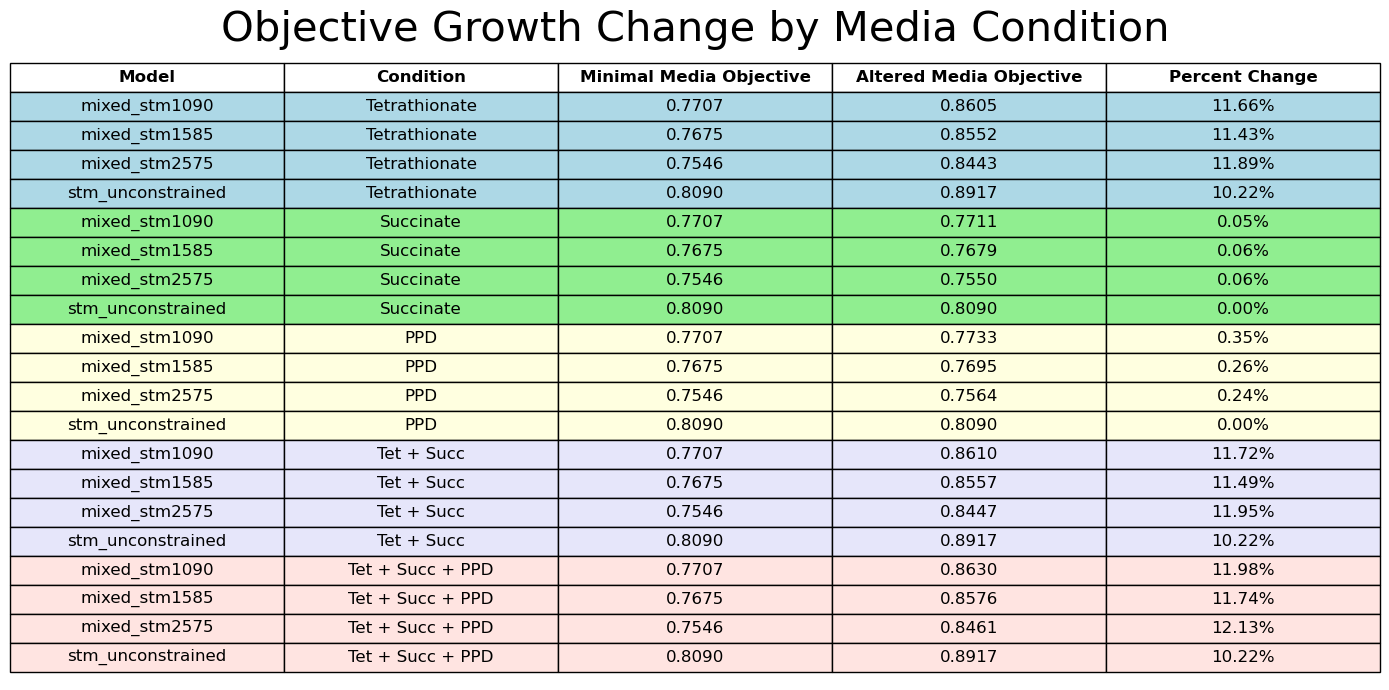

In [26]:
# save table as an image

import matplotlib.pyplot as plt

plot_dir = f"/home/gmvaz/2026_GEMs/stm_model_test/plots"

# Sort conditions in desired order
condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]

objective_table_df = (
    objective_change_df
    .with_columns(
        pl.col("Condition")
        .replace_strict(
            condition_order,
            list(range(len(condition_order)))
        )
        .alias("condition_order")
    )
    .sort(["condition_order", "Model"])
    .drop("condition_order")
)

# Colors for each condition
condition_colors = {
    "Tetrathionate": "lightblue",
    "Succinate": "lightgreen",
    "PPD": "lightyellow",
    "Tet + Succ": "lavender",
    "Tet + Succ + PPD": "mistyrose"
}

# Column names
columns = objective_table_df.columns

# Format table values
cell_text = []

for row in objective_table_df.iter_rows(named=True):

    cell_text.append([
        row["Model"],
        row["Condition"],
        f'{row["Minimal Media Objective"]:.4f}',
        f'{row["Altered Media Objective"]:.4f}',
        f'{row["Percent Change"]:.2f}%'
    ])

# Assign row colors by condition
cell_colors = []

for row in objective_table_df.iter_rows(named=True):

    color = condition_colors[row["Condition"]]

    cell_colors.append(
        [color] * len(columns)
    )

# Create table
fig, ax = plt.subplots(figsize=(14, 7))

ax.axis("off")

table = ax.table(
    cellText=cell_text,
    colLabels=columns,
    cellColours=cell_colors,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

# Format table
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.5)

# Format header
for col in range(len(columns)):
    table[(0, col)].set_text_props(weight="bold")

plt.title(
    "Objective Growth Change by Media Condition",
    fontsize=30,
    pad=10
)

plt.tight_layout()

# Save image
plt.savefig(
    f"{plot_dir}/objective_growth_change_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Plot Percent Change in Growth Rate

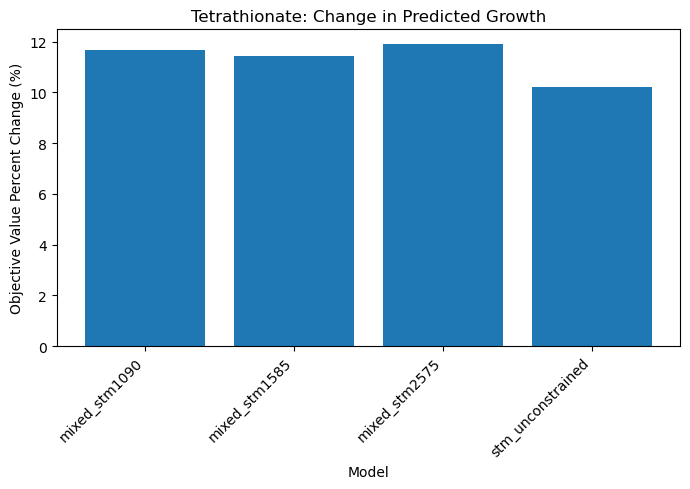

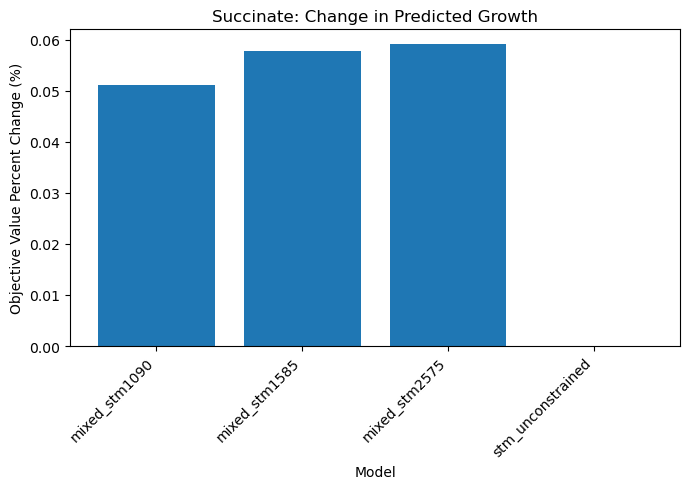

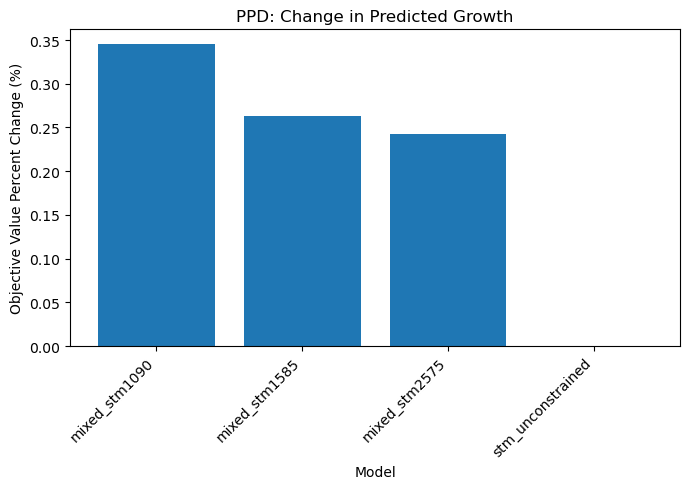

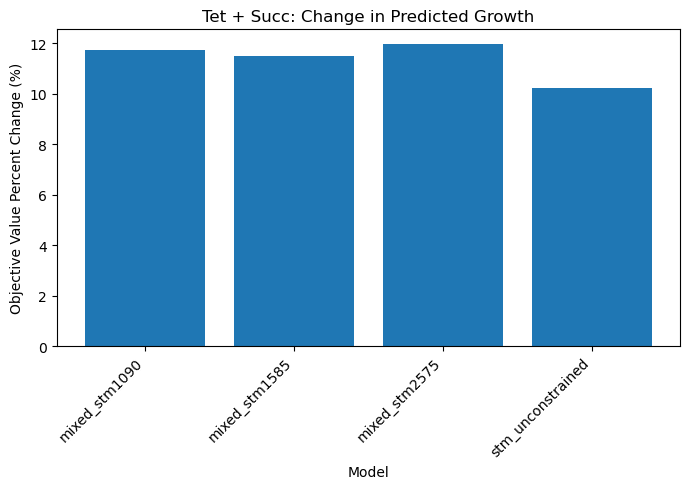

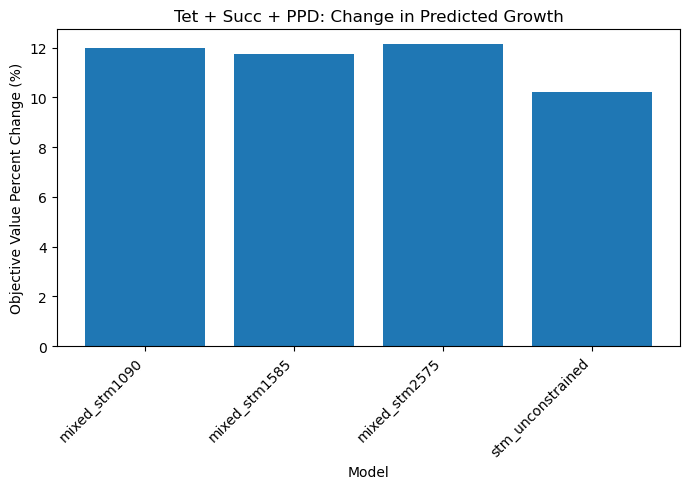

In [20]:
plot_dir = f"/home/gmvaz/2026_GEMs/stm_model_test/plots"

condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]

for condition in condition_order:

    condition_df = objective_change_df.filter(
        pl.col("Condition") == condition
    )

    plt.figure(figsize=(7, 5))

    plt.bar(
        condition_df["Model"].to_list(),
        condition_df["Percent Change"].to_list()
    )

    plt.ylabel("Objective Value Percent Change (%)")
    plt.xlabel("Model")
    plt.title(f"{condition}: Change in Predicted Growth")

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    file_name = condition.lower().replace(" ", "_").replace("+", "and")

    plt.savefig(
        f"{plot_dir}/{file_name}_growth_percent_change.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Uptake of Added Metabolites to the Medium

In [28]:
added_metabolite_flux_df = (
    flux_df

    # Get filename
    .with_columns(
        pl.col("filename")
        .str.extract(r"([^/]+)$", 1)
        .alias("file")
    )

    # Identify condition
    .with_columns(
        pl.when(pl.col("file").str.contains("_tet_succ_ppd_minimal_media_"))
        .then(pl.lit("Tet + Succ + PPD"))

        .when(pl.col("file").str.contains("_tet_and_succ_minimal_media_"))
        .then(pl.lit("Tet + Succ"))

        .when(pl.col("file").str.contains("_tet_minimal_media_"))
        .then(pl.lit("Tetrathionate"))

        .when(pl.col("file").str.contains("_succ_minimal_media_"))
        .then(pl.lit("Succinate"))

        .when(pl.col("file").str.contains("_ppd_minimal_media_"))
        .then(pl.lit("PPD"))

        .otherwise(pl.lit("Minimal Media"))
        .alias("Condition")
    )

    # Identify model
    .with_columns(
        pl.col("file")
        .str.replace(
            r"_(tet_succ_ppd|tet_and_succ|tet|succ|ppd)_minimal_media_solution_flux\.csv$",
            ""
        )
        .str.replace(
            r"_minimal_media_solution_flux\.csv$",
            ""
        )
        .alias("Model")
    )

    # Keep only metabolites added in each condition
    .filter(
        ((pl.col("Condition") == "Tetrathionate") &
         (pl.col("Reaction") == "EX_tet_e"))

        |

        ((pl.col("Condition") == "Succinate") &
         (pl.col("Reaction") == "EX_succ_e"))

        |

        ((pl.col("Condition") == "PPD") &
         pl.col("Reaction").is_in([
             "EX_12ppd__R_e",
             "EX_12ppd__S_e"
         ]))

        |

        ((pl.col("Condition") == "Tet + Succ") &
         pl.col("Reaction").is_in([
             "EX_tet_e",
             "EX_succ_e"
         ]))

        |

        ((pl.col("Condition") == "Tet + Succ + PPD") &
         pl.col("Reaction").is_in([
             "EX_tet_e",
             "EX_succ_e",
             "EX_12ppd__R_e",
             "EX_12ppd__S_e"
         ]))
    )

    # Add metabolite name and medium uptake bound
    .with_columns(
        pl.when(pl.col("Reaction") == "EX_tet_e")
        .then(pl.lit("Tetrathionate"))

        .when(pl.col("Reaction") == "EX_succ_e")
        .then(pl.lit("Succinate"))

        .when(pl.col("Reaction") == "EX_12ppd__R_e")
        .then(pl.lit("1,2-Propanediol R"))

        .when(pl.col("Reaction") == "EX_12ppd__S_e")
        .then(pl.lit("1,2-Propanediol S"))

        .alias("Added Metabolite"),

        pl.when(pl.col("Reaction") == "EX_tet_e")
        .then(pl.lit(4.0))

        .when(pl.col("Reaction") == "EX_succ_e")
        .then(pl.lit(3.0))

        .when(pl.col("Reaction").is_in([
            "EX_12ppd__R_e",
            "EX_12ppd__S_e"
        ]))
        .then(pl.lit(0.1))

        .alias("Medium Uptake Bound")
    )

    # Separate raw exchange flux into uptake and secretion
    .with_columns(
        pl.when(pl.col("Flux") < 0)
        .then(-pl.col("Flux"))
        .otherwise(0)
        .alias("Uptake Flux"),

        pl.when(pl.col("Flux") > 0)
        .then(pl.col("Flux"))
        .otherwise(0)
        .alias("Secretion Flux")
    )

    .select(
        "Model",
        "Condition",
        "Added Metabolite",
        "Reaction",
        "Reaction Name",
        "Medium Uptake Bound",
        "Uptake Flux",
        "Secretion Flux"
    )

    .sort([
        "Condition",
        "Added Metabolite",
        "Model"
    ])
)

added_metabolite_flux_df

Model,Condition,Added Metabolite,Reaction,Reaction Name,Medium Uptake Bound,Uptake Flux,Secretion Flux
str,str,str,str,str,f64,f64,f64
"""mixed_stm1090""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.0,0.01
"""mixed_stm1585""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.0,0.01
"""mixed_stm2575""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.01,0.0
"""stm_unconstrained""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.1,0.0
"""mixed_stm1090""","""PPD""","""1,2-Propanediol S""","""EX_12ppd__S_e""","""(S)-Propane-1,2-diol exchange""",0.1,0.1,0.0
…,…,…,…,…,…,…,…
"""stm_unconstrained""","""Tet + Succ + PPD""","""Tetrathionate""","""EX_tet_e""","""Tetrathionate exchange""",4.0,4.0,0.0
"""mixed_stm1090""","""Tetrathionate""","""Tetrathionate""","""EX_tet_e""","""Tetrathionate exchange""",4.0,4.0,0.0
"""mixed_stm1585""","""Tetrathionate""","""Tetrathionate""","""EX_tet_e""","""Tetrathionate exchange""",4.0,4.0,0.0


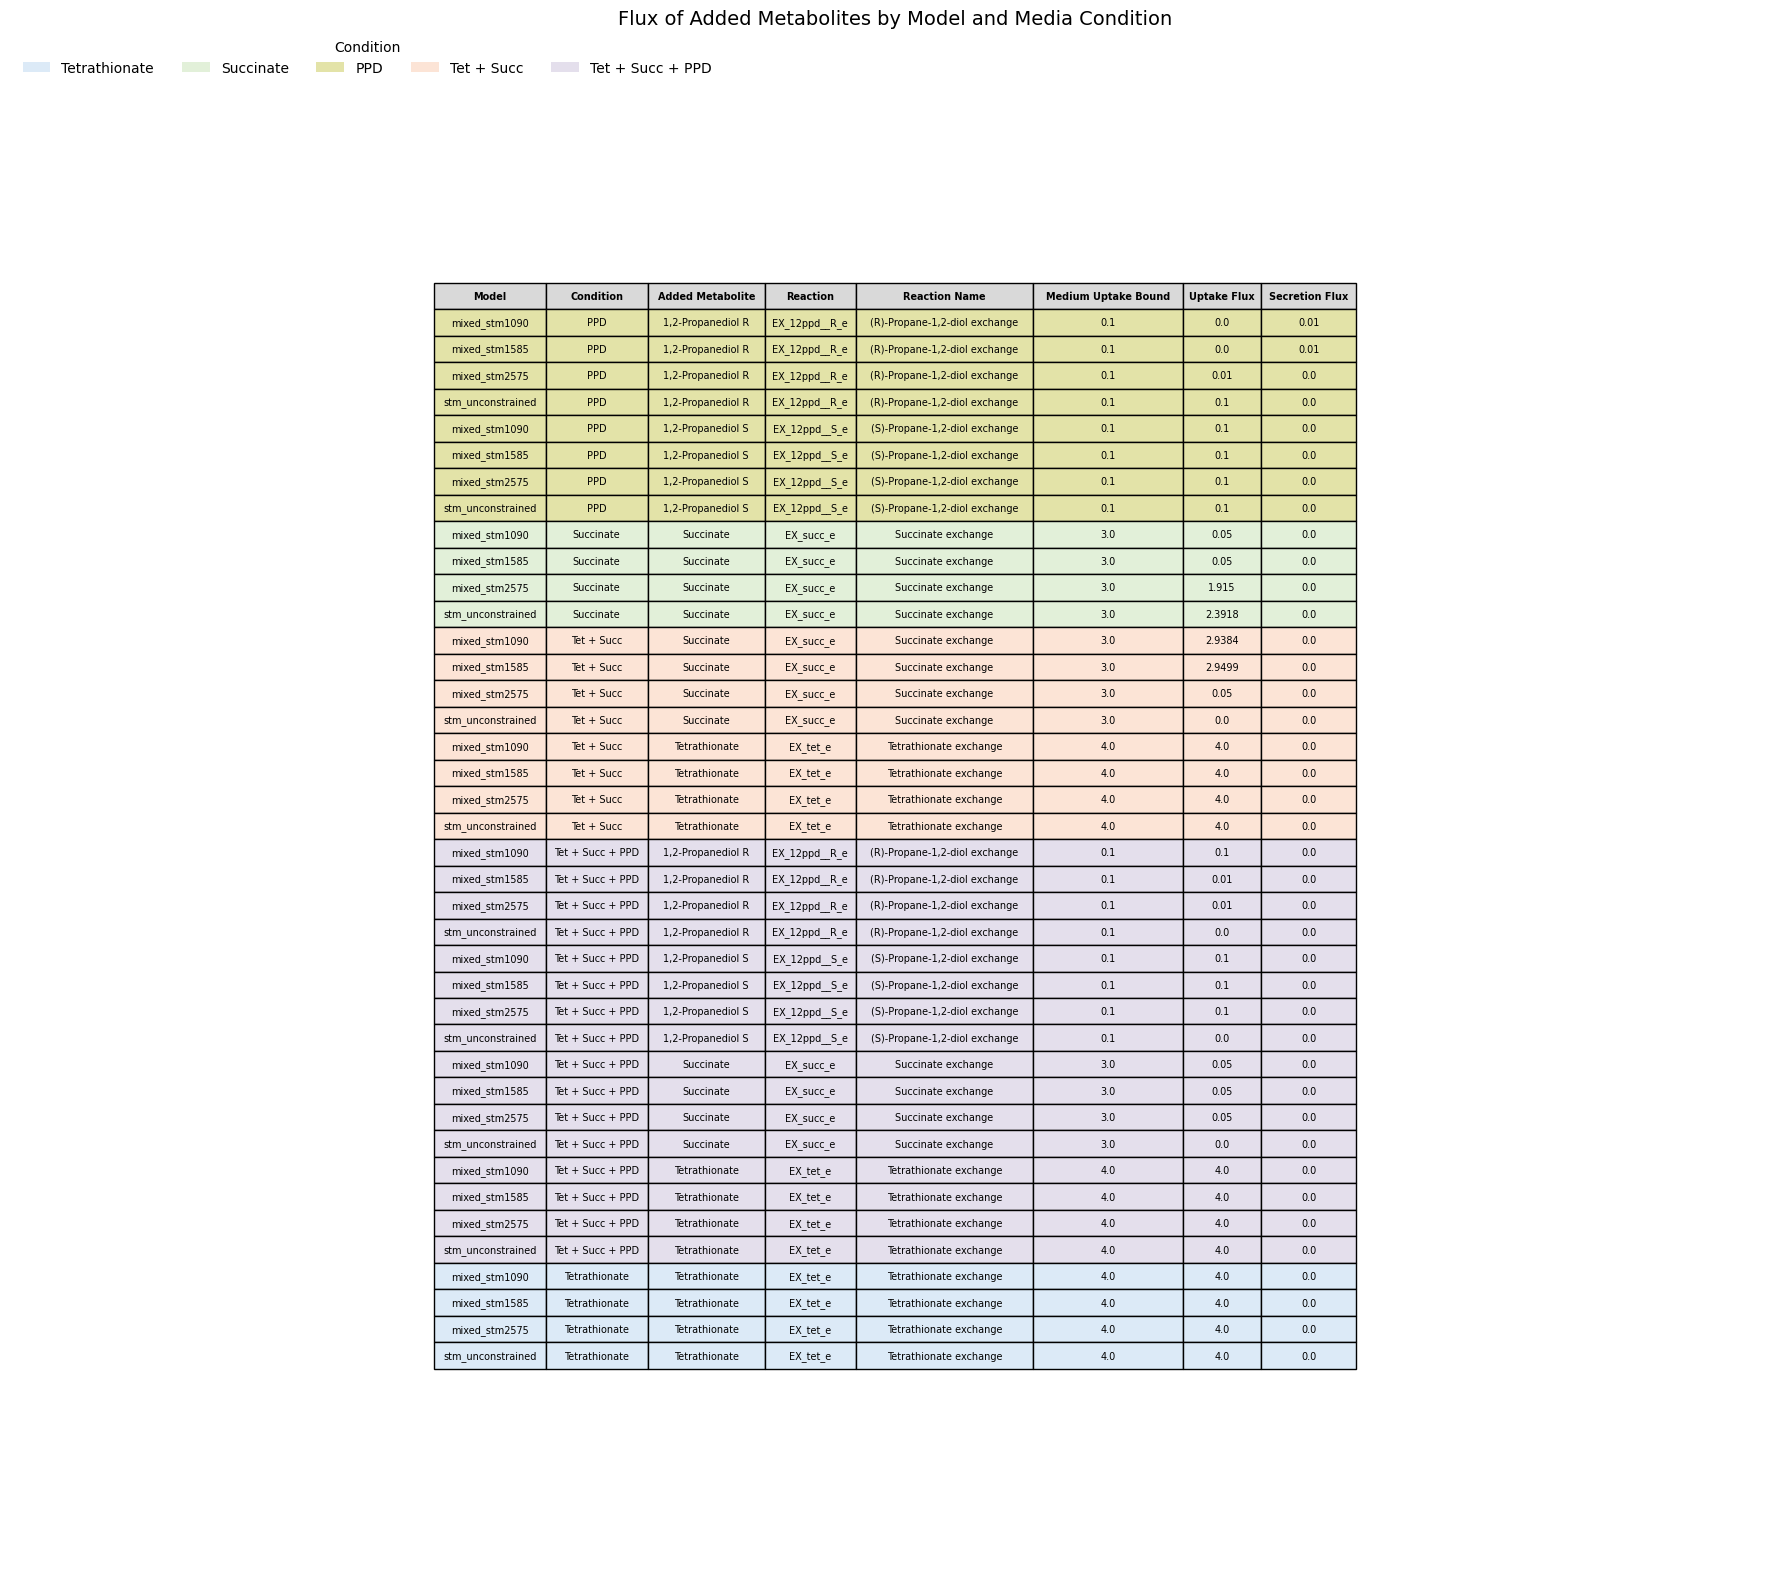

In [30]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Folder for saved table
plot_dir = f"/home/gmvaz/2026_GEMs/stm_model_test/plots"

# Colors for each media condition
condition_colors = {
    "Tetrathionate": "#DCEAF7",
    "Succinate": "#E2F0D9",
    "PPD": "#E3E3A8",
    "Tet + Succ": "#FCE4D6",
    "Tet + Succ + PPD": "#E4DFEC"
}

# Make a display copy and round numeric columns
table_df = added_metabolite_flux_df.with_columns(
    pl.col("Medium Uptake Bound").round(3),
    pl.col("Uptake Flux").round(4),
    pl.col("Secretion Flux").round(4)
)

# Table contents
cell_text = table_df.rows()
column_labels = table_df.columns

# Color each row according to condition
row_colors = [
    condition_colors[condition]
    for condition in table_df["Condition"].to_list()
]

cell_colors = [
    [color] * len(column_labels)
    for color in row_colors
]

# Create figure
fig, ax = plt.subplots(figsize=(18, 16))
ax.axis("off")

table = ax.table(
    cellText=cell_text,
    colLabels=column_labels,
    cellColours=cell_colors,
    colColours=["#D9D9D9"] * len(column_labels),
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(7)
table.scale(1, 1.3)

# Bold column headers
for col in range(len(column_labels)):
    table[(0, col)].set_text_props(weight="bold")

# Automatically adjust column widths
table.auto_set_column_width(
    col=list(range(len(column_labels)))
)

# Legend
legend_handles = [
    Patch(facecolor=color, label=condition)
    for condition, color in condition_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Condition",
    loc="upper left",
    bbox_to_anchor=(0, 1.03),
    ncol=5,
    frameon=False
)

plt.title(
    "Flux of Added Metabolites by Model and Media Condition",
    fontsize=14,
    pad=35
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/added_metabolite_flux_df.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

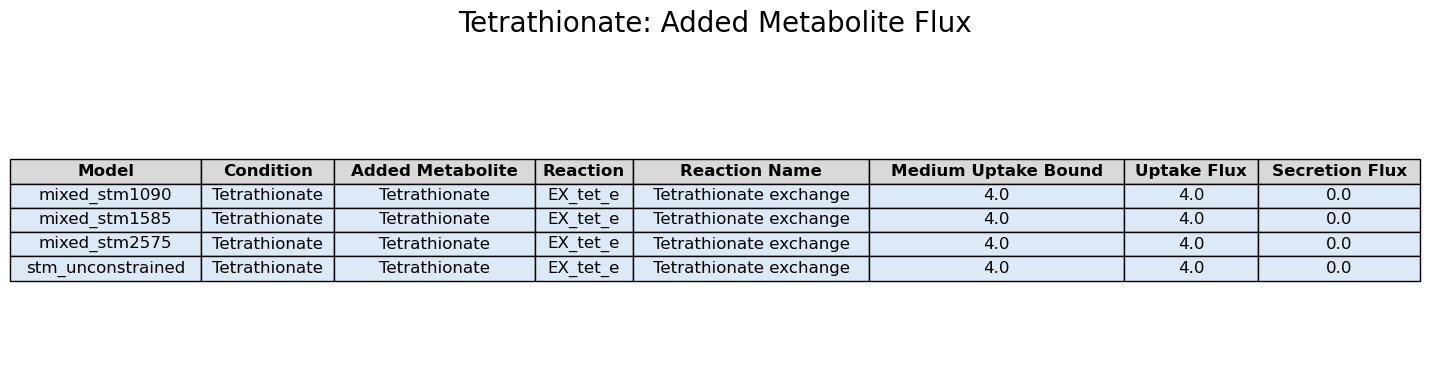

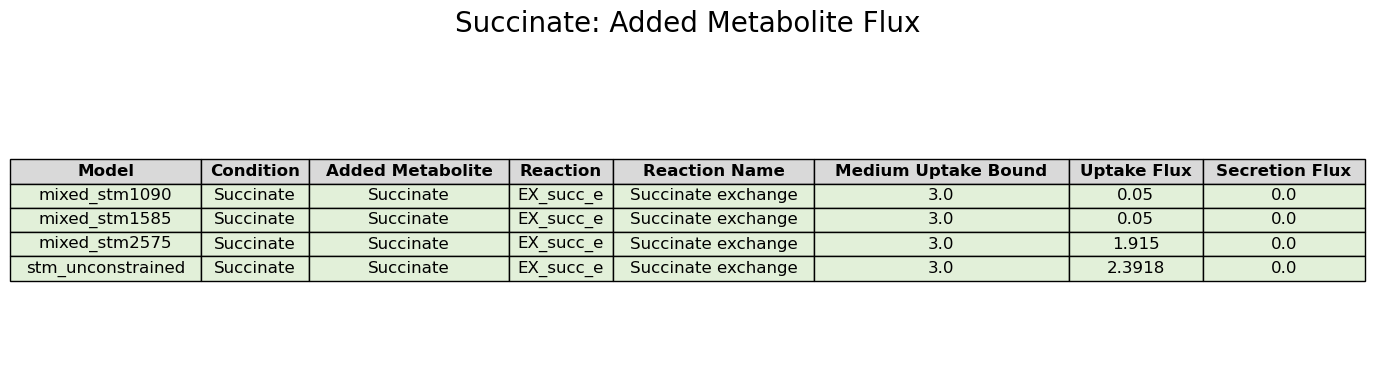

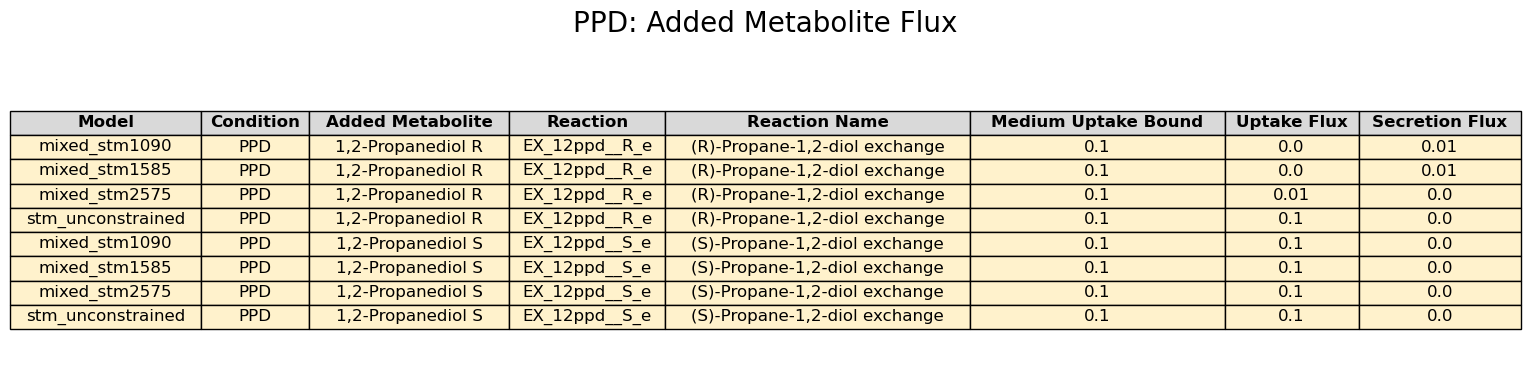

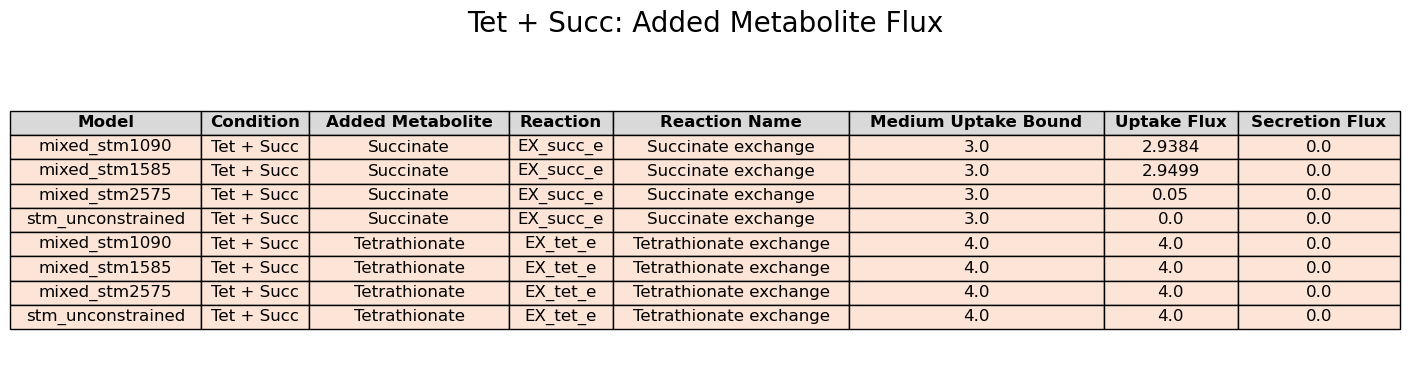

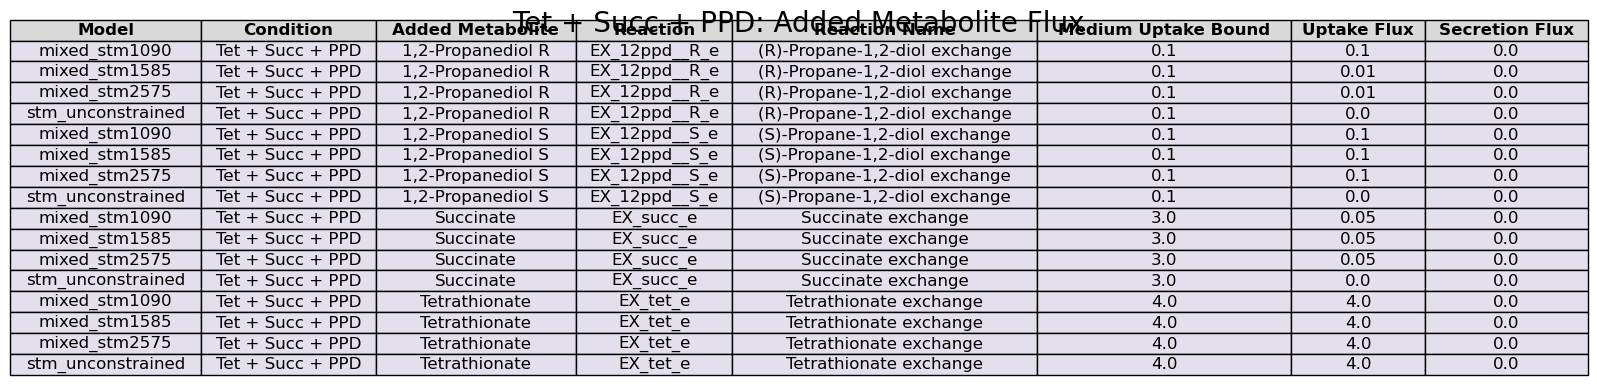

In [34]:
condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]

condition_colors = {
    "Tetrathionate": "#DCEAF7",
    "Succinate": "#E2F0D9",
    "PPD": "#FFF2CC",
    "Tet + Succ": "#FCE4D6",
    "Tet + Succ + PPD": "#E4DFEC"
}

for condition in condition_order:

    condition_df = (
        added_metabolite_flux_df
        .filter(pl.col("Condition") == condition)
        .with_columns(
            pl.col("Medium Uptake Bound").round(3),
            pl.col("Uptake Flux").round(4),
            pl.col("Secretion Flux").round(4)
        )
    )

    cell_text = condition_df.rows()
    column_labels = condition_df.columns

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.axis("off")

    table = ax.table(
        cellText=cell_text,
        colLabels=column_labels,
        cellLoc="center",
        loc="center",
        colColours=["#D9D9D9"] * len(column_labels)
    )

    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.4)

    # Color all data rows according to condition
    for row in range(1, len(cell_text) + 1):
        for col in range(len(column_labels)):
            table[(row, col)].set_facecolor(
                condition_colors[condition]
            )

    # Bold headers
    for col in range(len(column_labels)):
        table[(0, col)].set_text_props(weight="bold")

    table.auto_set_column_width(
        col=list(range(len(column_labels)))
    )

    plt.title(
        f"{condition}: Added Metabolite Flux",
        fontsize=20,
        pad=20
    )

    plt.tight_layout()

    file_name = (
        condition.lower()
        .replace(" ", "_")
        .replace("+", "and")
    )

    plt.savefig(
        f"{plot_dir}/{file_name}_added_metabolite_flux_table.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Comparing added metabolite utilization across conditions

In [35]:
uptake_comparison_df = (
    added_metabolite_flux_df

    .select(
        "Model",
        "Added Metabolite",
        "Condition",
        "Medium Uptake Bound",
        "Uptake Flux"
    )

    .sort([
        "Added Metabolite",
        "Model",
        "Condition"
    ])
)

uptake_comparison_df

Model,Added Metabolite,Condition,Medium Uptake Bound,Uptake Flux
str,str,str,f64,f64
"""mixed_stm1090""","""1,2-Propanediol R""","""PPD""",0.1,0.0
"""mixed_stm1090""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.1
"""mixed_stm1585""","""1,2-Propanediol R""","""PPD""",0.1,0.0
"""mixed_stm1585""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.01
"""mixed_stm2575""","""1,2-Propanediol R""","""PPD""",0.1,0.01
…,…,…,…,…
"""mixed_stm2575""","""Tetrathionate""","""Tet + Succ + PPD""",4.0,4.0
"""mixed_stm2575""","""Tetrathionate""","""Tetrathionate""",4.0,4.0
"""stm_unconstrained""","""Tetrathionate""","""Tet + Succ""",4.0,4.0


In [36]:
uptake_comparison_wide_df = (
    uptake_comparison_df

    .pivot(
        on="Condition",
        index=[
            "Model",
            "Added Metabolite"
        ],
        values="Uptake Flux",
        aggregate_function="first"
    )

    .sort([
        "Added Metabolite",
        "Model"
    ])
)

uptake_comparison_wide_df

Model,Added Metabolite,PPD,Tet + Succ + PPD,Succinate,Tet + Succ,Tetrathionate
str,str,f64,f64,f64,f64,f64
"""mixed_stm1090""","""1,2-Propanediol R""",0.0,0.1,null,null,null
"""mixed_stm1585""","""1,2-Propanediol R""",0.0,0.01,null,null,null
"""mixed_stm2575""","""1,2-Propanediol R""",0.01,0.01,null,null,null
"""stm_unconstrained""","""1,2-Propanediol R""",0.1,0.0,null,null,null
"""mixed_stm1090""","""1,2-Propanediol S""",0.1,0.1,null,null,null
…,…,…,…,…,…,…
"""stm_unconstrained""","""Succinate""",null,0.0,2.391792,0.0,null
"""mixed_stm1090""","""Tetrathionate""",null,4.0,null,4.0,4.0
"""mixed_stm1585""","""Tetrathionate""",null,4.0,null,4.0,4.0


In [37]:
uptake_comparison_df = (
    added_metabolite_flux_df

    .with_columns(
        (
            pl.col("Uptake Flux")
            / pl.col("Medium Uptake Bound")
            * 100
        ).alias("Percent of Uptake Bound Used")
    )

    .select(
        "Model",
        "Added Metabolite",
        "Condition",
        "Medium Uptake Bound",
        "Uptake Flux",
        "Percent of Uptake Bound Used"
    )

    .sort([
        "Added Metabolite",
        "Model",
        "Condition"
    ])
)

uptake_comparison_df

Model,Added Metabolite,Condition,Medium Uptake Bound,Uptake Flux,Percent of Uptake Bound Used
str,str,str,f64,f64,f64
"""mixed_stm1090""","""1,2-Propanediol R""","""PPD""",0.1,0.0,0.0
"""mixed_stm1090""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.1,100.0
"""mixed_stm1585""","""1,2-Propanediol R""","""PPD""",0.1,0.0,0.0
"""mixed_stm1585""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.01,10.0
"""mixed_stm2575""","""1,2-Propanediol R""","""PPD""",0.1,0.01,10.0
…,…,…,…,…,…
"""mixed_stm2575""","""Tetrathionate""","""Tet + Succ + PPD""",4.0,4.0,100.0
"""mixed_stm2575""","""Tetrathionate""","""Tetrathionate""",4.0,4.0,100.0
"""stm_unconstrained""","""Tetrathionate""","""Tet + Succ""",4.0,4.0,100.0


In [38]:
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(uptake_comparison_df)

shape: (40, 6)
┌────────────────┬────────────────┬────────────────┬────────────────┬─────────────┬────────────────┐
│ Model          ┆ Added          ┆ Condition      ┆ Medium Uptake  ┆ Uptake Flux ┆ Percent of     │
│ ---            ┆ Metabolite     ┆ ---            ┆ Bound          ┆ ---         ┆ Uptake Bound   │
│ str            ┆ ---            ┆ str            ┆ ---            ┆ f64         ┆ Used           │
│                ┆ str            ┆                ┆ f64            ┆             ┆ ---            │
│                ┆                ┆                ┆                ┆             ┆ f64            │
╞════════════════╪════════════════╪════════════════╪════════════════╪═════════════╪════════════════╡
│ mixed_stm1090  ┆ 1,2-Propanedio ┆ PPD            ┆ 0.1            ┆ 0.0         ┆ 0.0            │
│                ┆ l R            ┆                ┆                ┆             ┆                │
│ mixed_stm1090  ┆ 1,2-Propanedio ┆ Tet + Succ +   ┆ 0.1            ┆ 0.1   

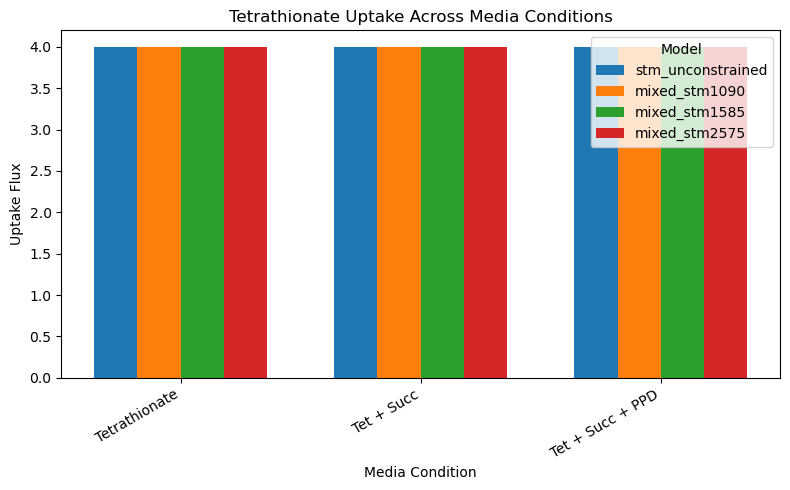

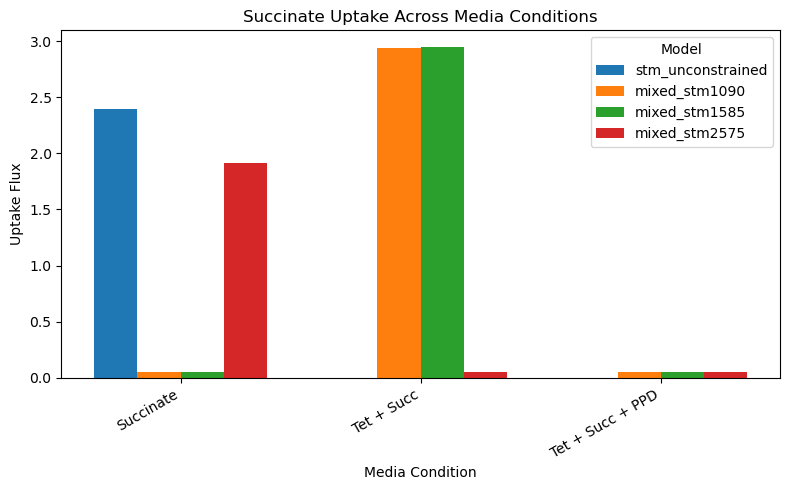

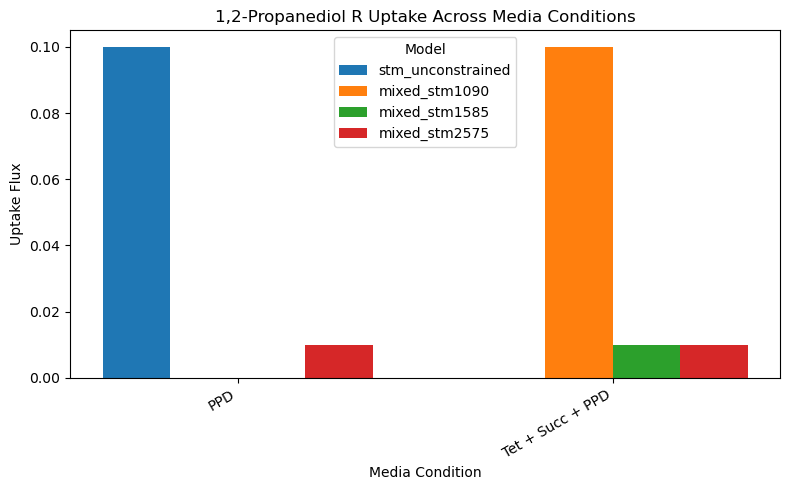

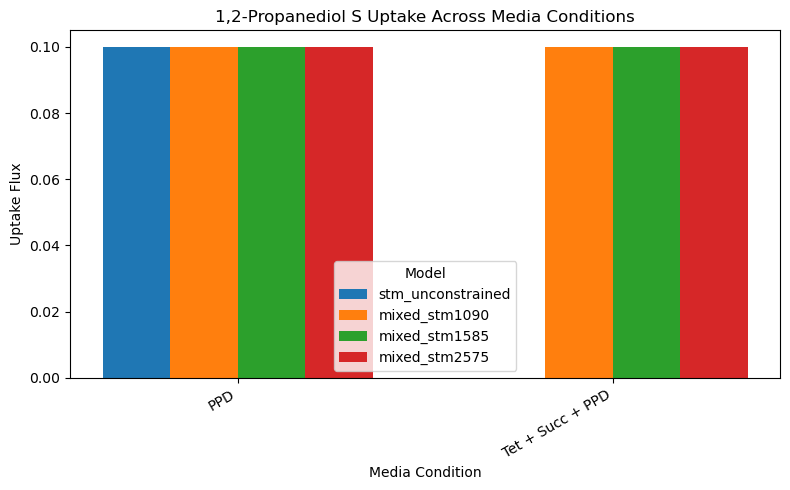

In [39]:
import numpy as np
import matplotlib.pyplot as plt

metabolites = [
    "Tetrathionate",
    "Succinate",
    "1,2-Propanediol R",
    "1,2-Propanediol S"
]

models = [
    "stm_unconstrained",
    "mixed_stm1090",
    "mixed_stm1585",
    "mixed_stm2575"
]

condition_order = {
    "Tetrathionate": [
        "Tetrathionate",
        "Tet + Succ",
        "Tet + Succ + PPD"
    ],
    "Succinate": [
        "Succinate",
        "Tet + Succ",
        "Tet + Succ + PPD"
    ],
    "1,2-Propanediol R": [
        "PPD",
        "Tet + Succ + PPD"
    ],
    "1,2-Propanediol S": [
        "PPD",
        "Tet + Succ + PPD"
    ]
}

for metabolite in metabolites:

    metabolite_df = uptake_comparison_df.filter(
        pl.col("Added Metabolite") == metabolite
    )

    conditions = condition_order[metabolite]

    x = np.arange(len(conditions))
    width = 0.18

    plt.figure(figsize=(8, 5))

    for i, model in enumerate(models):

        model_df = metabolite_df.filter(
            pl.col("Model") == model
        )

        uptake_values = []

        for condition in conditions:

            value = (
                model_df
                .filter(pl.col("Condition") == condition)
                ["Uptake Flux"]
                .to_list()
            )

            uptake_values.append(value[0] if value else 0)

        plt.bar(
            x + (i - 1.5) * width,
            uptake_values,
            width,
            label=model
        )

    plt.xticks(
        x,
        conditions,
        rotation=30,
        ha="right"
    )

    plt.ylabel("Uptake Flux")
    plt.xlabel("Media Condition")
    plt.title(f"{metabolite} Uptake Across Media Conditions")

    plt.legend(title="Model")
    plt.tight_layout()

    plt.show()

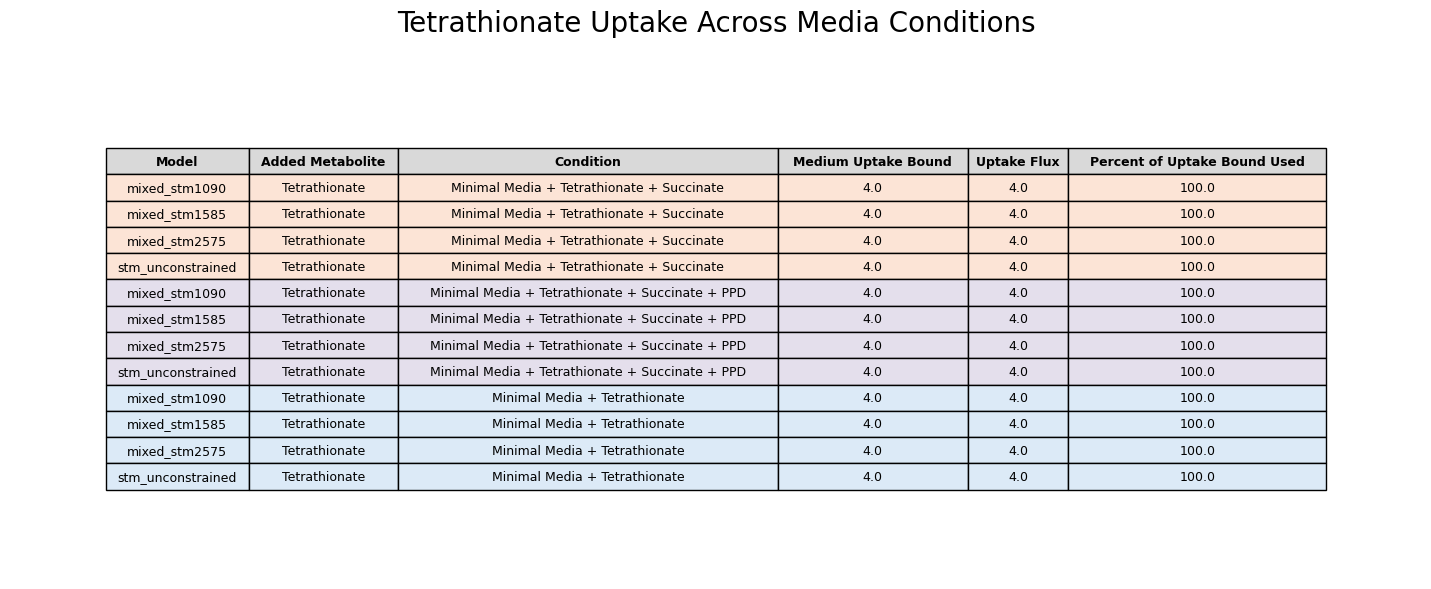

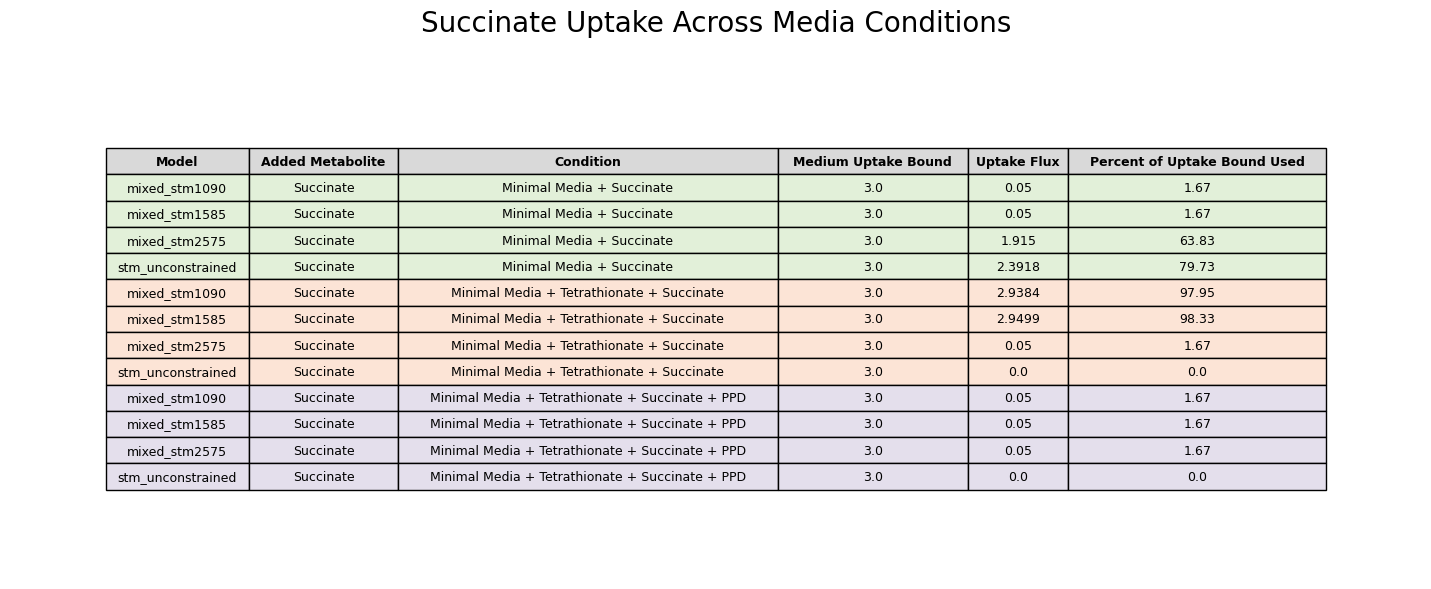

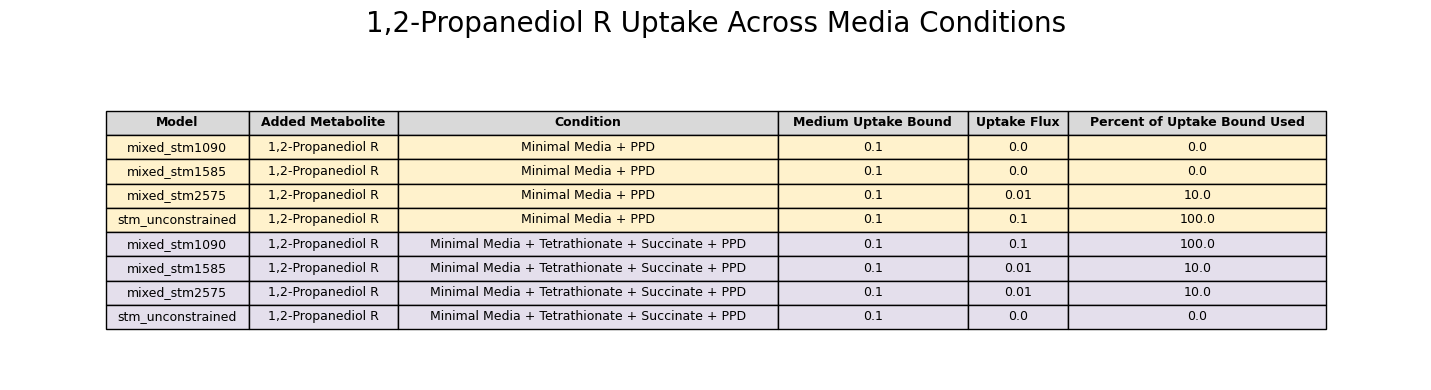

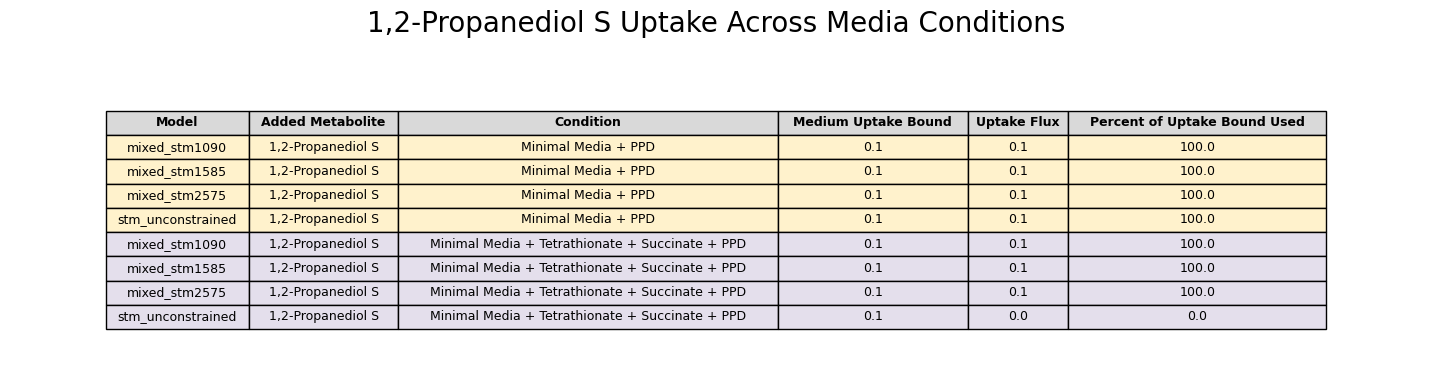

In [43]:
condition_descriptions = {
    "Tetrathionate": "Minimal Media + Tetrathionate",
    "Succinate": "Minimal Media + Succinate",
    "PPD": "Minimal Media + PPD",
    "Tet + Succ": "Minimal Media + Tetrathionate + Succinate",
    "Tet + Succ + PPD": "Minimal Media + Tetrathionate + Succinate + PPD"
}

condition_colors = {
    "Tetrathionate": "#DCEAF7",
    "Succinate": "#E2F0D9",
    "PPD": "#FFF2CC",
    "Tet + Succ": "#FCE4D6",
    "Tet + Succ + PPD": "#E4DFEC"
}

metabolites = [
    "Tetrathionate",
    "Succinate",
    "1,2-Propanediol R",
    "1,2-Propanediol S"
]

for metabolite in metabolites:

    metabolite_df = (
        uptake_comparison_df
        .filter(pl.col("Added Metabolite") == metabolite)
        .sort(["Condition", "Model"])
    )

    # Save original condition values for coloring
    conditions = metabolite_df["Condition"].to_list()

    # Replace condition names with full media descriptions
    metabolite_df = metabolite_df.with_columns(
        pl.col("Condition")
        .replace(condition_descriptions)
        .alias("Condition"),

        pl.col("Medium Uptake Bound").round(3),
        pl.col("Uptake Flux").round(4),
        pl.col("Percent of Uptake Bound Used").round(2)
    )

    cell_text = metabolite_df.rows()
    column_labels = metabolite_df.columns

    fig_height = max(4, len(cell_text) * 0.5)

    fig, ax = plt.subplots(figsize=(15, fig_height))
    ax.axis("off")

    table = ax.table(
        cellText=cell_text,
        colLabels=column_labels,
        cellLoc="center",
        loc="center",
        colColours=["#D9D9D9"] * len(column_labels)
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.4)

    # Color each row according to media condition
    for row, condition in enumerate(conditions, start=1):
        for col in range(len(column_labels)):
            table[(row, col)].set_facecolor(
                condition_colors[condition]
            )

    # Bold headers
    for col in range(len(column_labels)):
        table[(0, col)].set_text_props(weight="bold")

    table.auto_set_column_width(
        col=list(range(len(column_labels)))
    )

    plt.title(
        f"{metabolite} Uptake Across Media Conditions",
        fontsize=20,
        pad=20
    )

    plt.tight_layout()

    file_name = (
        metabolite.lower()
        .replace(" ", "_")
        .replace(",", "")
        .replace("-", "_")
    )

    plt.savefig(
        f"{plot_dir}/{file_name}_uptake_comparison_table.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()